In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


# Predict Airline Satisfaction

## Load dataset and Analyse

### V2 - Automated Ensemble Modelling

Loading data...
Competition training dataset: (699635, 23)
Competition test dataset: (299844, 22)

Target: satisfaction
ID: id
Modeling feature count: 21
Duplicate train rows: 0
Duplicate test rows : 0

Target distribution:


,label,count,percentage
0,Not satisfied,389296,55.642728
1,Satisfied,310339,44.357272


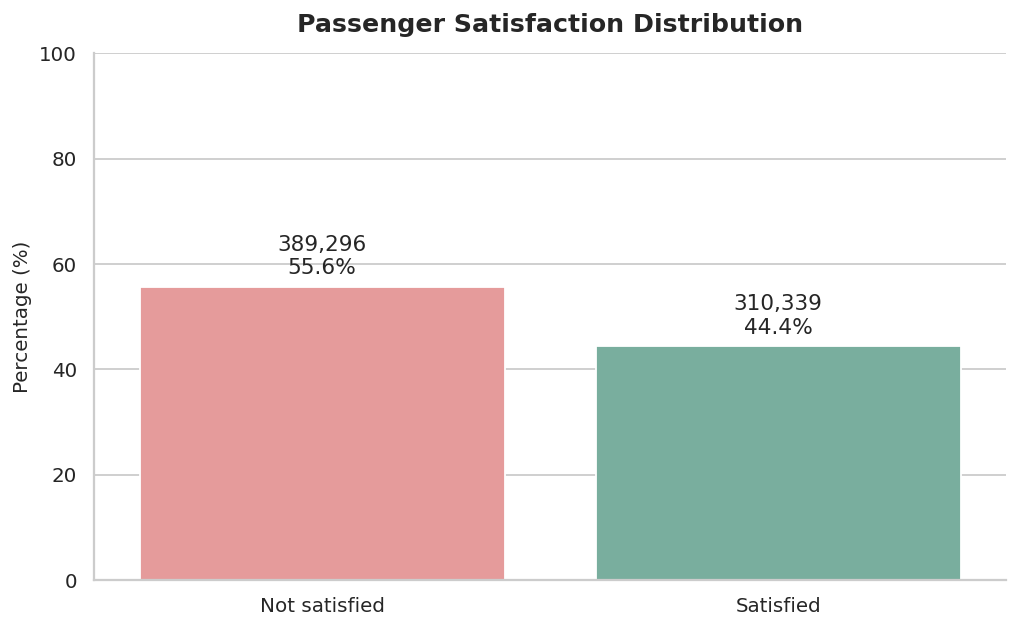

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import TargetEncoder
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
import xgboost as xgb
import catboost as cb

warnings.filterwarnings('ignore')

# Notebook-wide visual defaults.
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 130
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.family"] = "DejaVu Sans"

# ---------------------------------------------------------
# 1. Load Data and Analyse
# ---------------------------------------------------------
print("Loading data...")
train = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/train.csv")
test = pd.read_csv("/kaggle/input/competitions/playground-series-s6e10/test.csv")

target_col = "satisfaction"
id_col = "id"

if target_col not in train.columns:
    raise ValueError(f"Target column {target_col!r} not found in train.csv")

if id_col not in train.columns:
    print(f"Warning: ID column {id_col!r} not found in train.csv")

if id_col not in test.columns:
    print(f"Warning: ID column {id_col!r} not found in test.csv")

# Define target and modeling features.
y = train[target_col]
feature_cols = [
    col for col in train.columns
    if col not in {target_col, id_col}
]

print("Competition training dataset:", train.shape)
print("Competition test dataset:", test.shape)
print("\nTarget:", target_col)
print("ID:", id_col)
print("Modeling feature count:", len(feature_cols))
print("Duplicate train rows:", train.duplicated().sum())
print("Duplicate test rows :", test.duplicated().sum())

print("\nTarget distribution:")

# Map boolean target values to readable labels
label_map = {
    True: "Satisfied",
    False: "Not satisfied",
}

# Build counts and percentages, preserving the desired label order
counts = y.map(label_map).value_counts().reindex(
    ["Not satisfied", "Satisfied"],
    fill_value=0,
)

target_distribution = pd.DataFrame({
    "label": counts.index,
    "count": counts.values,
})
target_distribution["percentage"] = (
    target_distribution["count"] / len(y) * 100
)

display(target_distribution)

fig, ax = plt.subplots(figsize=(8, 5))

sns.barplot(
    data=target_distribution,
    x="label",
    y="percentage",
    hue="label",
    order=["Not satisfied", "Satisfied"],
    palette={"Not satisfied": "#F28E8E", "Satisfied": "#70B7A1"},
    legend=False,
    ax=ax,
)

ax.set_title("Passenger Satisfaction Distribution", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Percentage (%)")
ax.set_ylim(0, 100)

# Add count and percentage labels to each bar
for bar, row in zip(ax.patches, target_distribution.itertuples()):
    ax.annotate(
        f"{row.count:,}\n{row.percentage:.1f}%",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        xytext=(0, 5),
        textcoords="offset points",
    )

sns.despine()
plt.tight_layout()
plt.show()

## Basic Exploratory Data Analysis

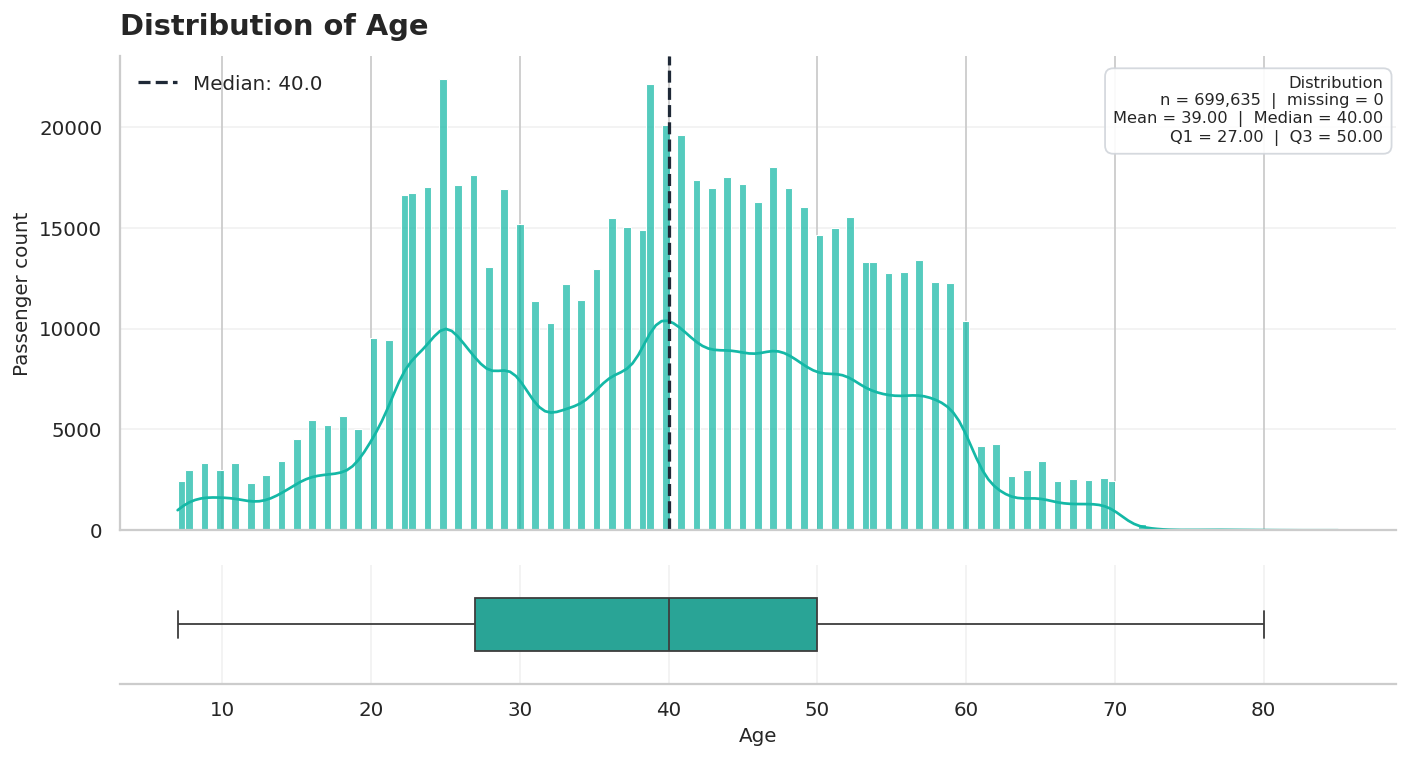

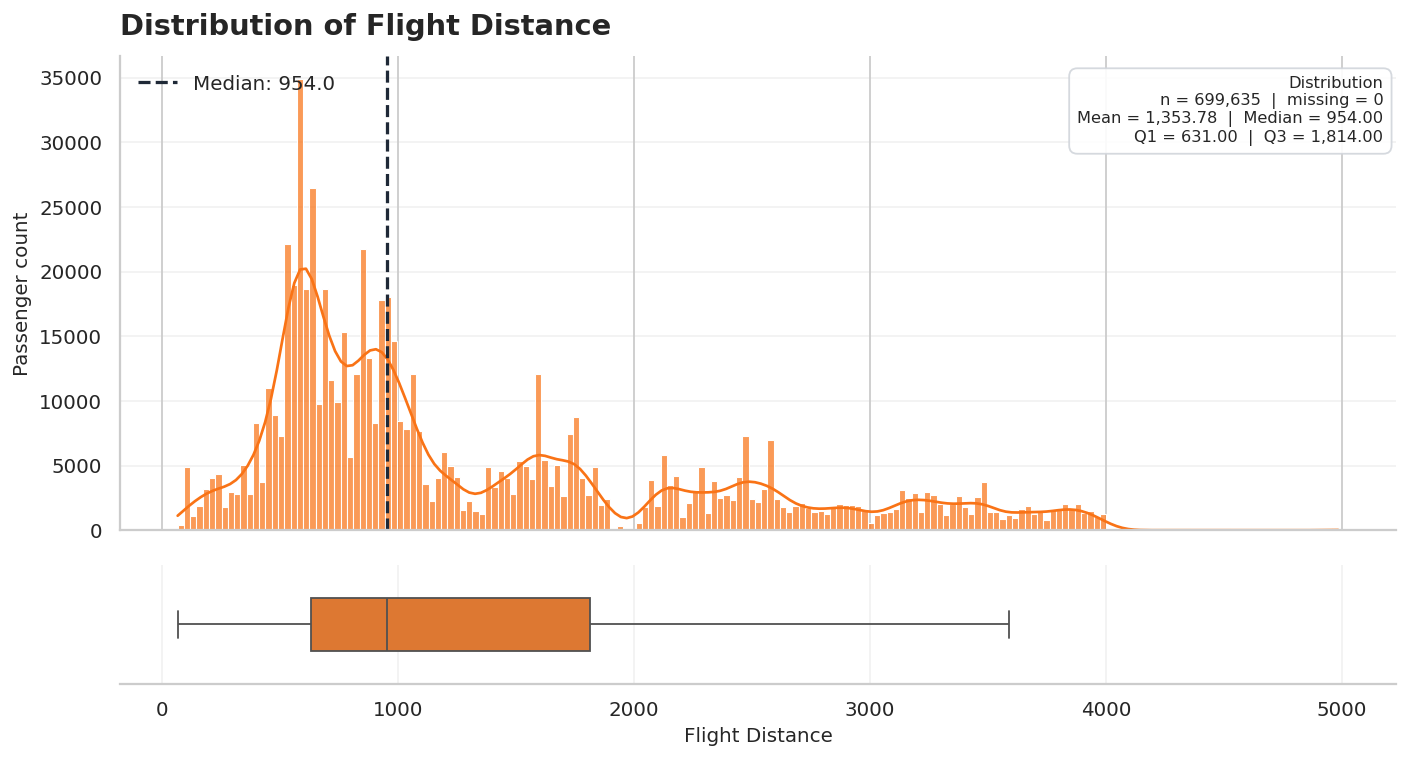

Highest average rating: Baggage handling (3.81)
Lowest average rating: Inflight wifi service (2.78)

Service summary:


,Mean rating,Share rating 4–5,Valid response share
Baggage handling,3.81,0.69,1.0
Seat comfort,3.57,0.60,1.0
On-board service,3.52,0.57,1.0
Leg room service,3.47,0.55,1.0
Inflight entertainment,3.45,0.56,1.0
Checkin service,3.42,0.51,1.0
Cleanliness,3.38,0.51,1.0
Online boarding,3.36,0.52,1.0
Food and drink,3.27,0.46,1.0
Departure/Arrival time convenient,3.16,0.48,1.0


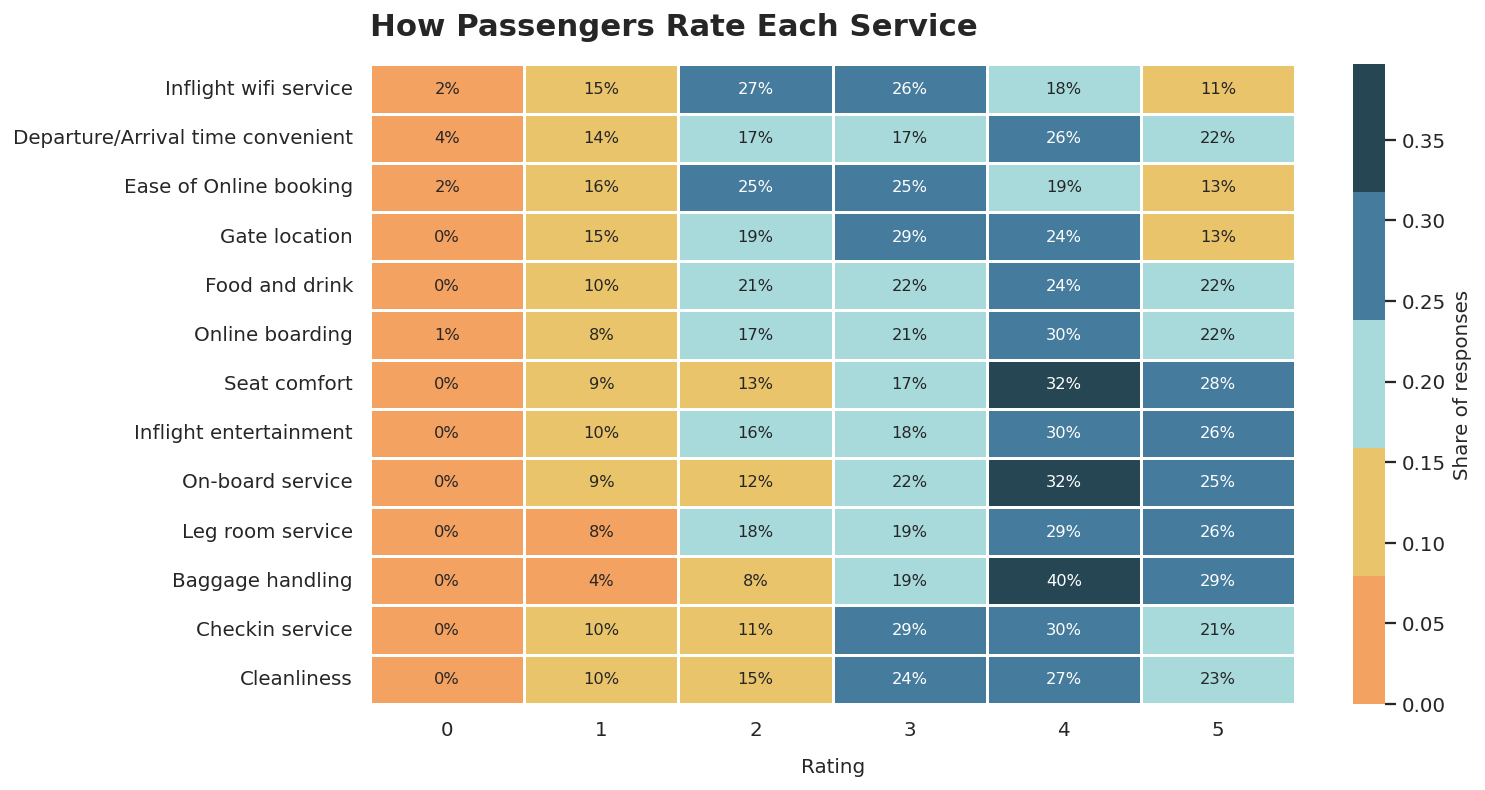

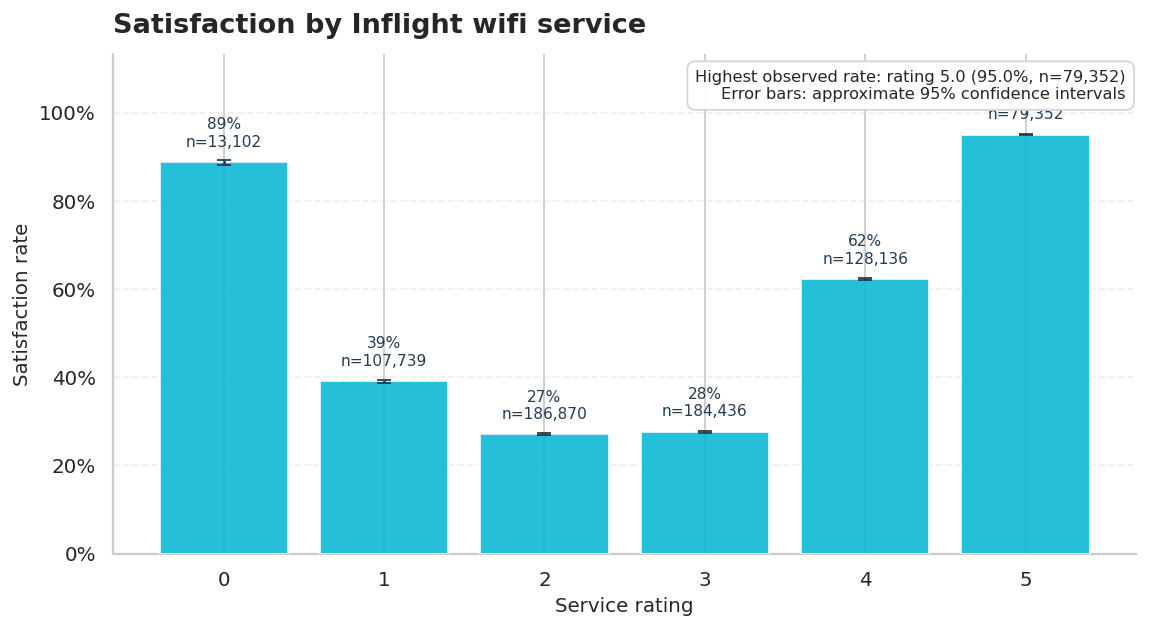

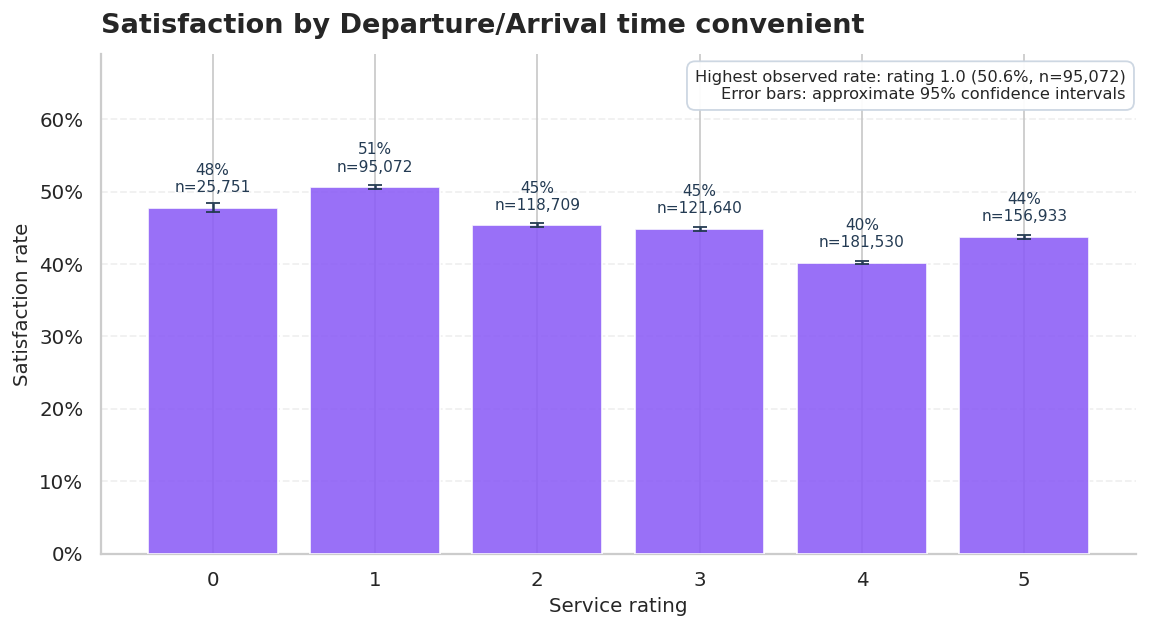

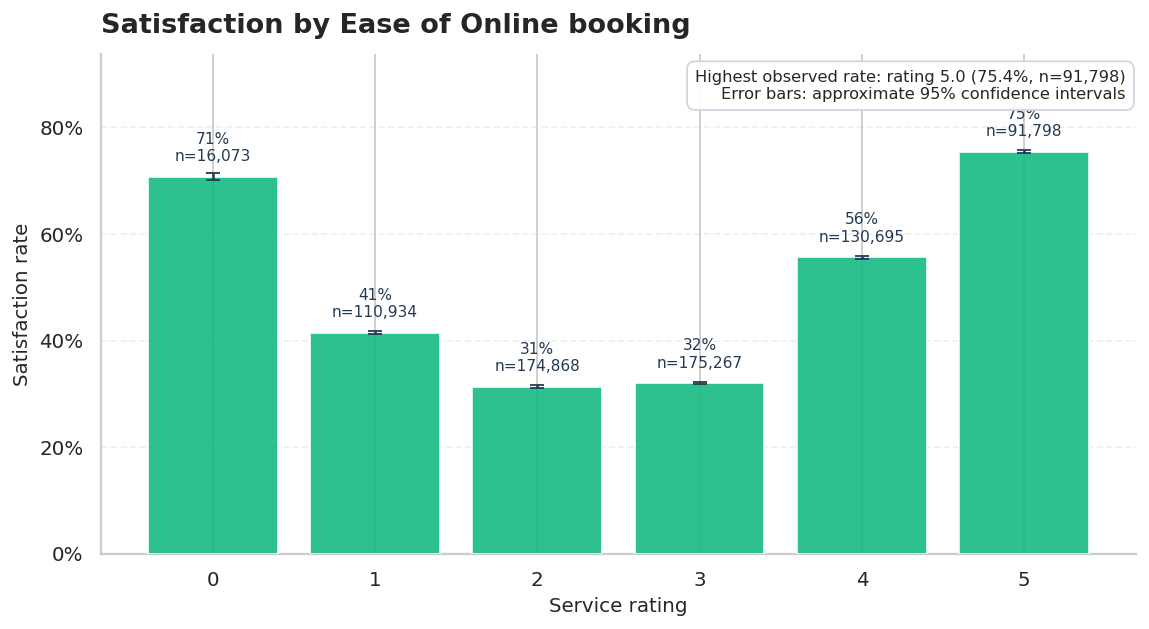

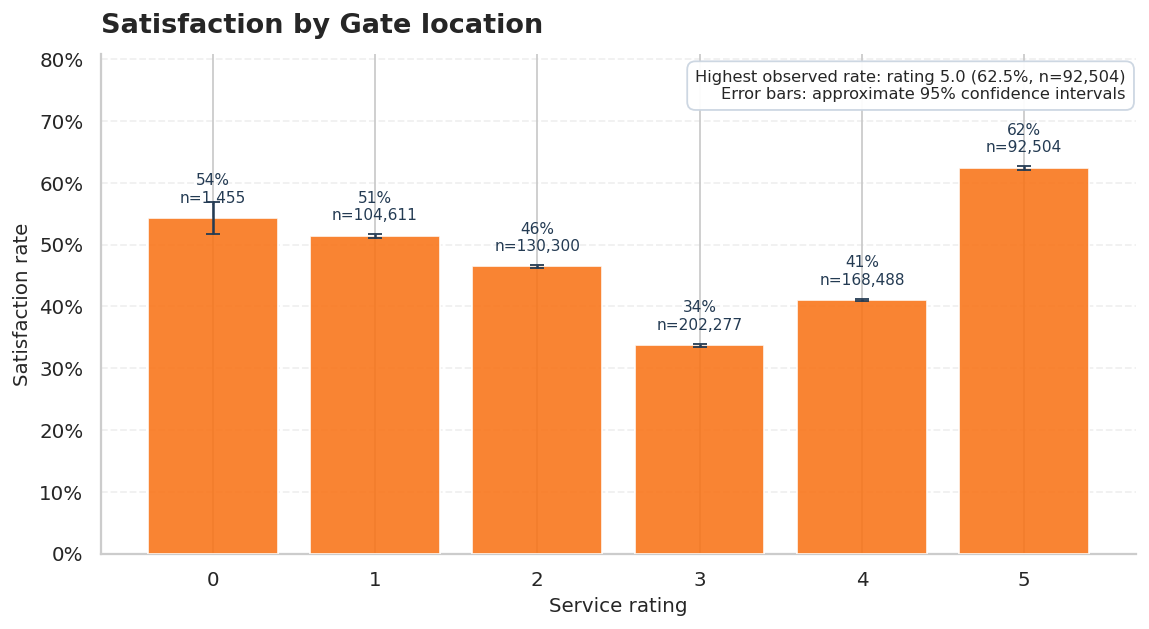

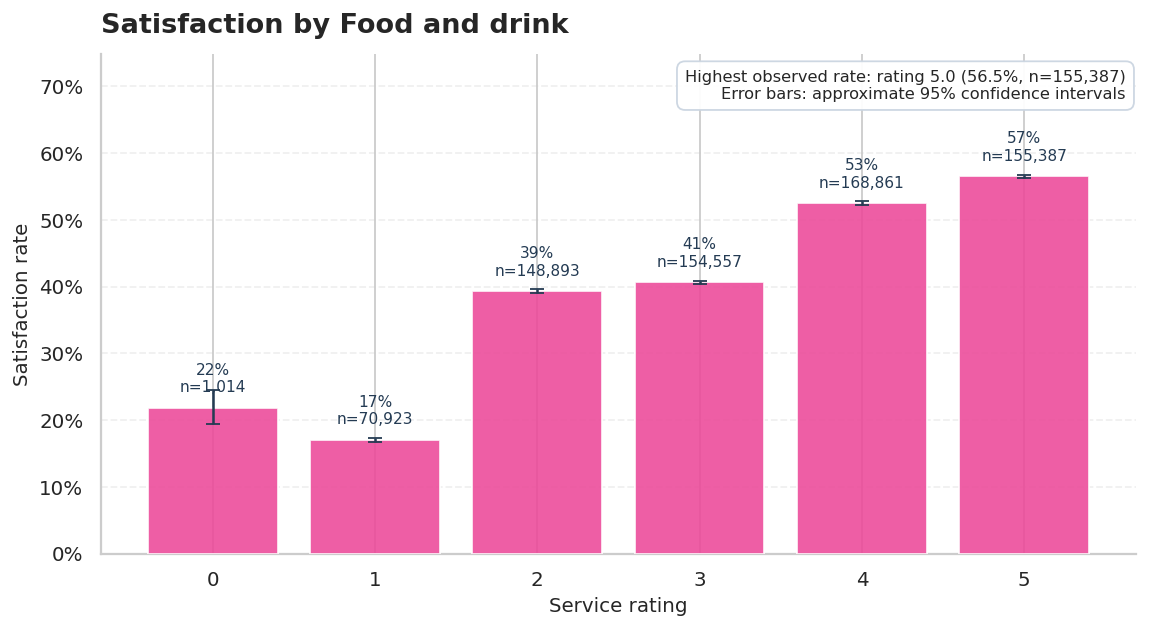

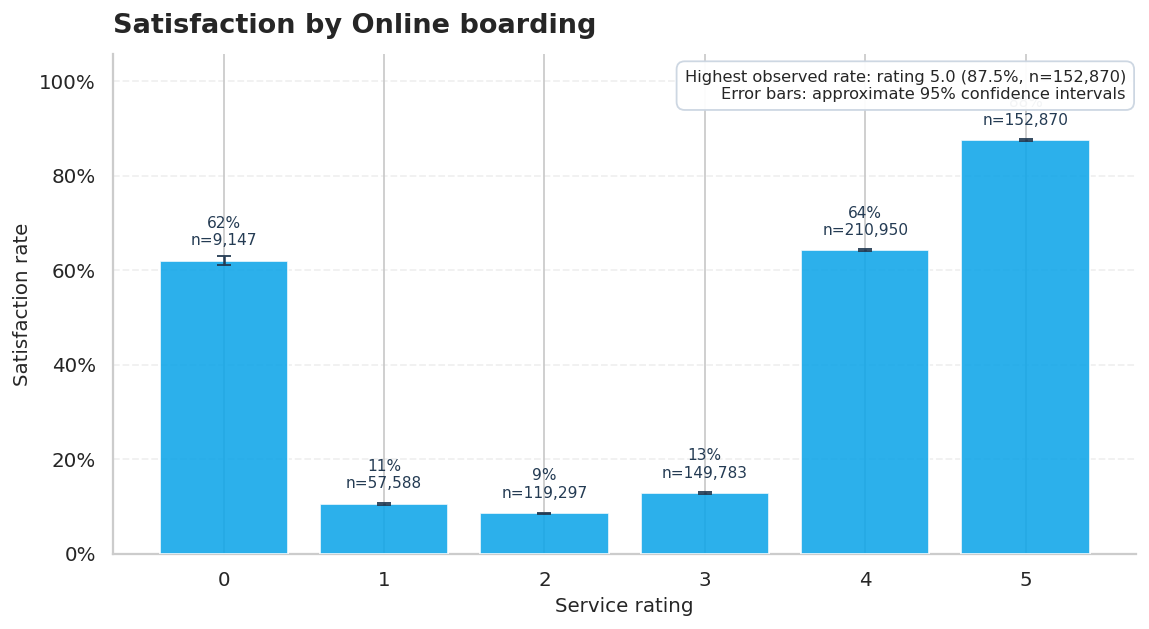

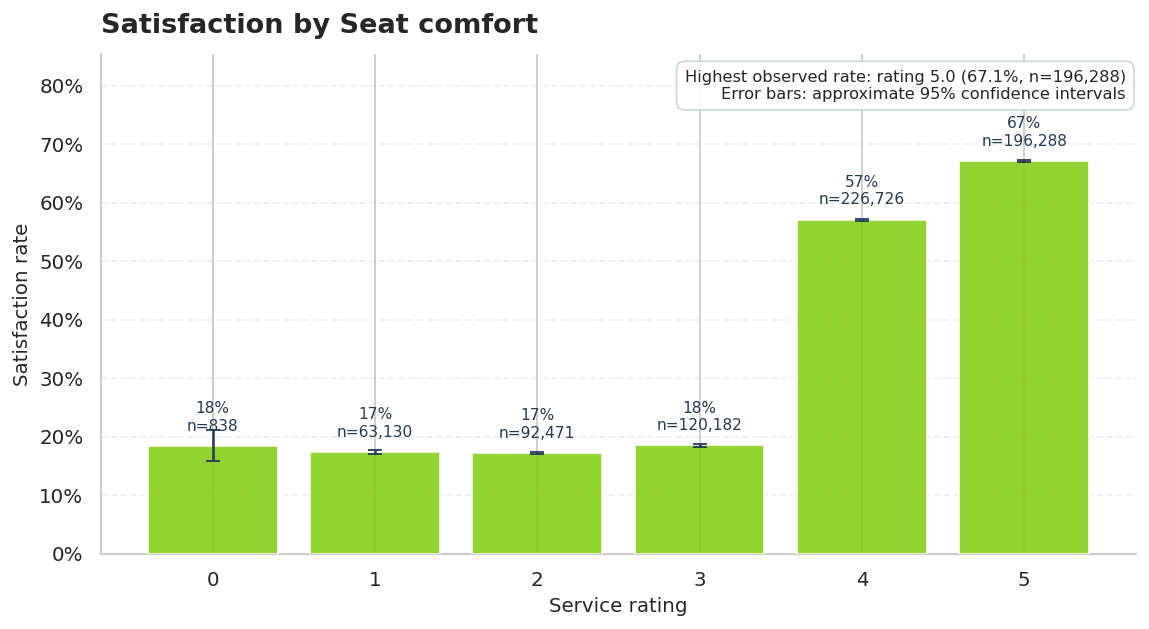

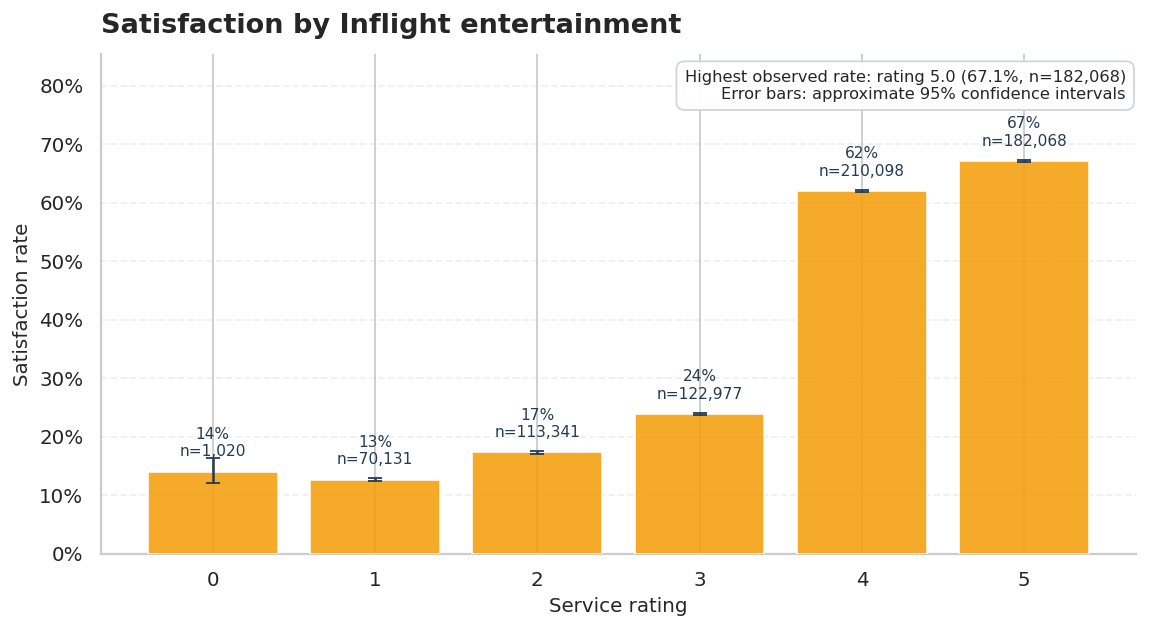

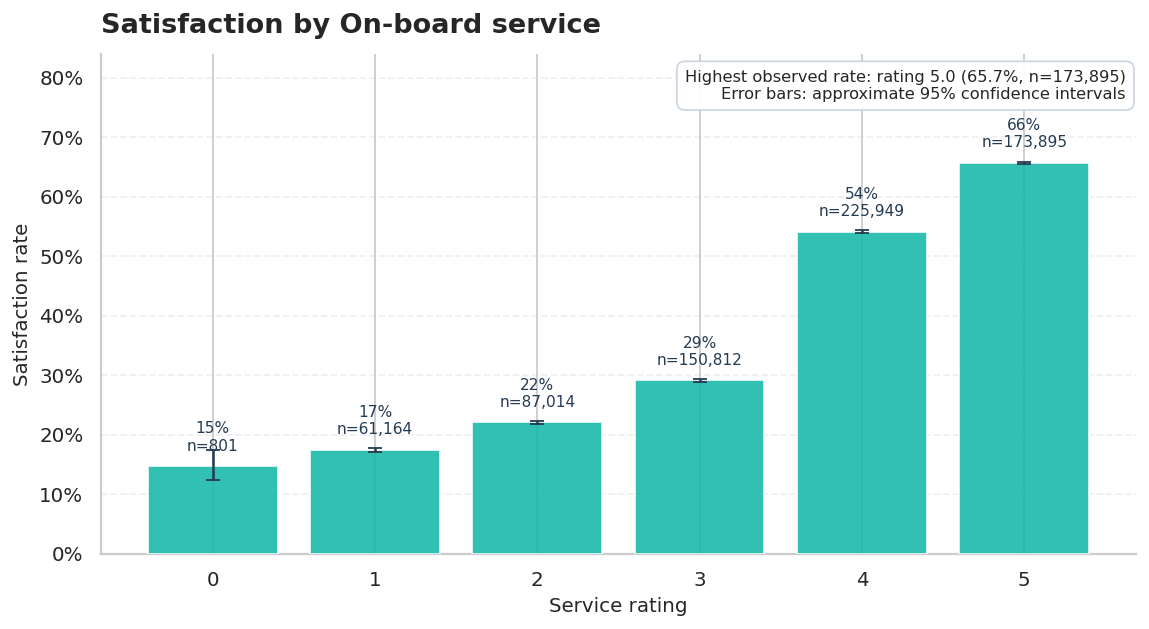

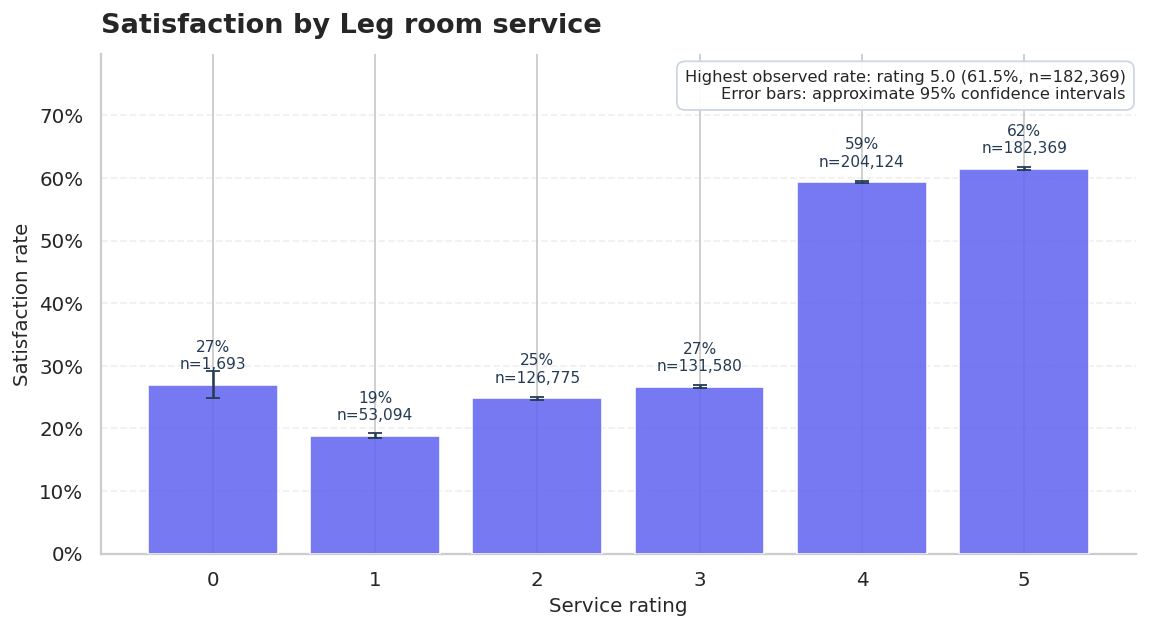

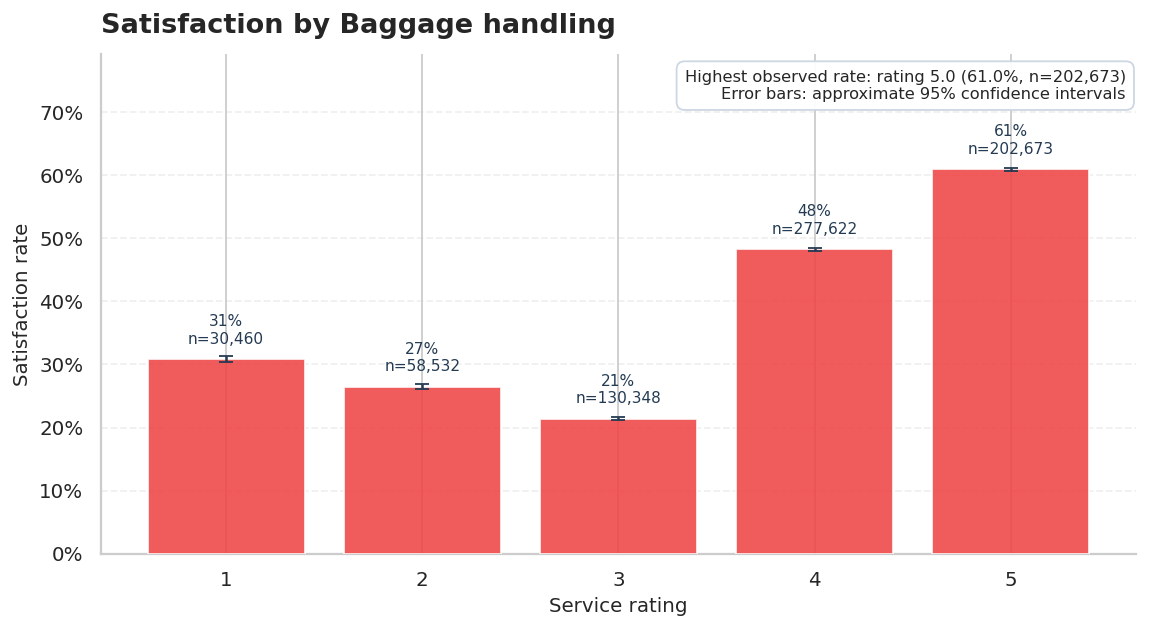

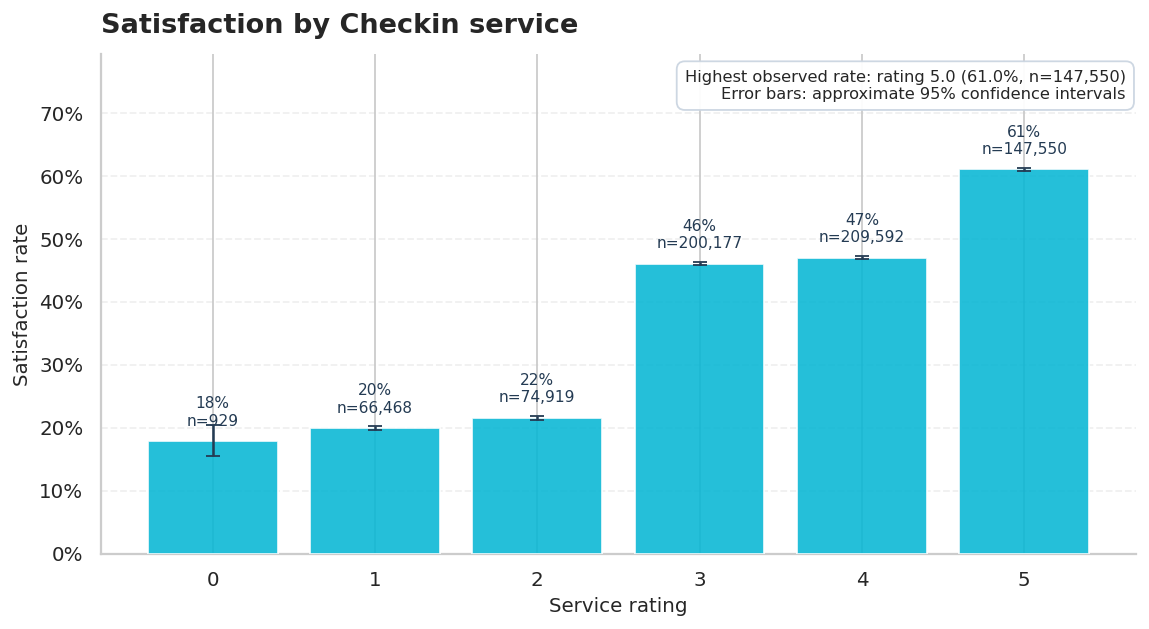

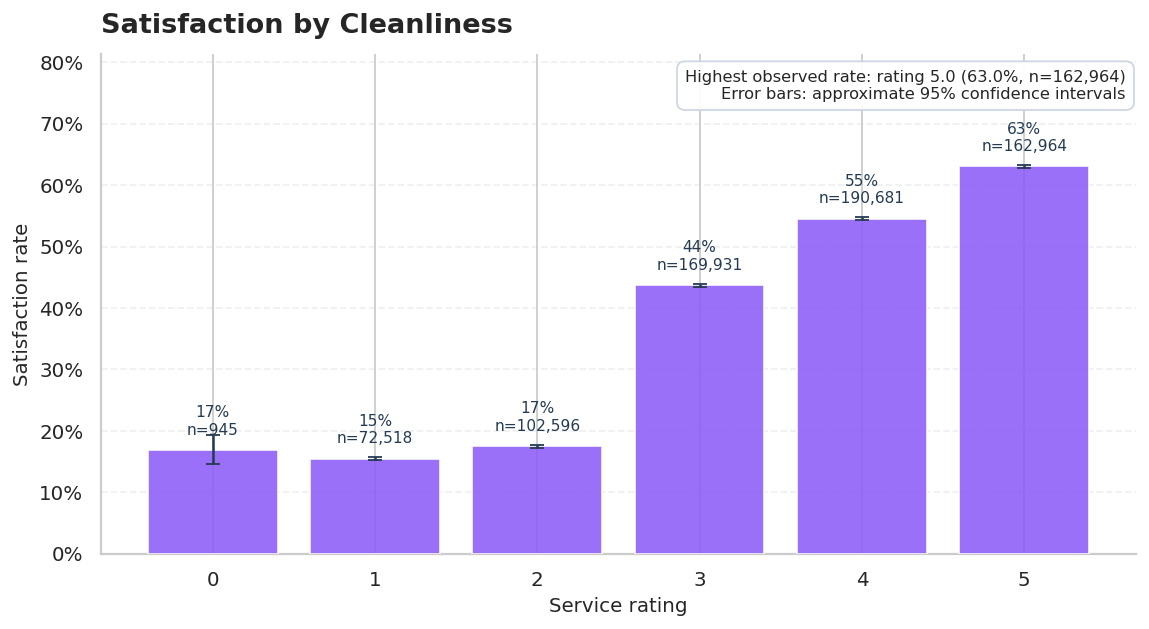

In [3]:
# ---------------------------------------------------------
# 2. Exploratory Data Analysis
# ---------------------------------------------------------

eda_numeric = [
    col for col in [
        "Age",
        "Flight Distance",
    ]
    if col in train.columns
]

plot_colors = {
    "Age": "#14B8A6",
    "Flight Distance": "#F97316",
}

# Set True to include a compact boxplot beneath each histogram
SHOW_BOXPLOT = True

for col in eda_numeric:
    data = train[col].dropna()

    if data.empty:
        print(f"Skipping {col}: no non-missing values.")
        continue

    # Clip only the displayed delay values; summary statistics use all data
    if "Delay" in col:
        upper = data.quantile(0.99)
        data_plot = data[data <= upper]
        view_label = f"Display capped at 99th percentile ({upper:,.1f})"
    else:
        data_plot = data
        view_label = "Distribution"

    color = plot_colors.get(col, "#6366F1")
    n = len(data)
    missing = train[col].isna().sum()

    # Summary statistics based on all non-missing values
    stats = (
        f"n = {n:,}  |  missing = {missing:,}\n"
        f"Mean = {data.mean():,.2f}  |  Median = {data.median():,.2f}\n"
        f"Q1 = {data.quantile(0.25):,.2f}  |  Q3 = {data.quantile(0.75):,.2f}"
    )

    if SHOW_BOXPLOT:
        fig, (ax_hist, ax_box) = plt.subplots(
            2, 1,
            figsize=(11, 6),
            gridspec_kw={"height_ratios": [4, 1]},
            sharex=True,
        )
    else:
        fig, ax_hist = plt.subplots(figsize=(11, 5))
        ax_box = None

    # Histogram and KDE
    sns.histplot(
        data_plot,
        bins="auto",
        kde=data_plot.nunique() > 1,
        color=color,
        alpha=0.72,
        edgecolor="white",
        linewidth=0.6,
        ax=ax_hist,
    )

    ax_hist.axvline(
        data.median(),
        color="#1F2937",
        linestyle="--",
        linewidth=1.8,
        label=f"Median: {data.median():,.1f}",
    )

    ax_hist.set_title(
        f"Distribution of {col}",
        fontsize=16,
        fontweight="bold",
        loc="left",
        pad=12,
    )
    ax_hist.set_xlabel("")
    ax_hist.set_ylabel("Passenger count")
    ax_hist.text(
        0.99, 0.96,
        f"{view_label}\n{stats}",
        transform=ax_hist.transAxes,
        ha="right",
        va="top",
        fontsize=9,
        bbox={
            "boxstyle": "round,pad=0.5",
            "facecolor": "white",
            "edgecolor": "#D1D5DB",
            "alpha": 0.9,
        },
    )
    ax_hist.legend(frameon=False, loc="upper left")
    ax_hist.grid(axis="y", alpha=0.25)
    sns.despine(ax=ax_hist)

    # Boxplot uses the same displayed values as the histogram
    if ax_box is not None:
        sns.boxplot(
            x=data_plot,
            color=color,
            width=0.45,
            showfliers=False,
            ax=ax_box,
        )
        ax_box.set_xlabel(col)
        ax_box.set_ylabel("")
        ax_box.set_yticks([])
        ax_box.grid(axis="x", alpha=0.25)
        sns.despine(ax=ax_box, left=True)

    fig.tight_layout()
    plt.show()

# --------------------------------
# Service-rating distribution plot
# --------------------------------
rating_cols = [
    col for col in [
        "Inflight wifi service",
        "Departure/Arrival time convenient",
        "Ease of Online booking",
        "Gate location",
        "Food and drink",
        "Online boarding",
        "Seat comfort",
        "Inflight entertainment",
        "On-board service",
        "Leg room service",
        "Baggage handling",
        "Checkin service",
        "Cleanliness",
    ]
    if col in train.columns
]

if rating_cols:
    rating_matrix = pd.DataFrame({
        col: train[col].value_counts(normalize=True).sort_index()
        for col in rating_cols
    }).T.fillna(0)

    rating_matrix.columns = [str(value) for value in rating_matrix.columns]

    # Service-level summaries for quick comparison
    numeric_ratings = train[rating_cols].apply(pd.to_numeric, errors="coerce")
    mean_rating = numeric_ratings.mean()
    positive_share = numeric_ratings.ge(4).mean()  # Ratings 4–5, where applicable
    valid_share = numeric_ratings.notna().mean()

    service_summary = pd.DataFrame({
        "Mean rating": mean_rating,
        "Share rating 4–5": positive_share,
        "Valid response share": valid_share,
    }).dropna(subset=["Mean rating"])

    if not service_summary.empty:
        best_service = service_summary["Mean rating"].idxmax()
        lowest_service = service_summary["Mean rating"].idxmin()

        print(f"Highest average rating: {best_service} "
              f"({service_summary.loc[best_service, 'Mean rating']:.2f})")
        print(f"Lowest average rating: {lowest_service} "
              f"({service_summary.loc[lowest_service, 'Mean rating']:.2f})")

        print("\nService summary:")
        display(
            service_summary.sort_values("Mean rating", ascending=False)
            .round(2)
        )

    fig_height = max(6, 0.48 * len(rating_cols))
    fig, ax = plt.subplots(figsize=(12, fig_height))

    sns.heatmap(
        rating_matrix,
        annot=True,
        fmt=".0%",
        cmap=sns.color_palette(
            ["#F4A261", "#E9C46A", "#A8DADC", "#457B9D", "#264653"],
            as_cmap=True,
        ),
        linewidths=0.7,
        linecolor="white",
        vmin=0,
        vmax=max(0.01, rating_matrix.to_numpy().max()),
        cbar_kws={"label": "Share of responses"},
        annot_kws={"size": 9},
        ax=ax,
    )

    ax.set_title(
        "How Passengers Rate Each Service",
        fontsize=17,
        fontweight="bold",
        loc="left",
        pad=16,
    )
    ax.set_xlabel("Rating", labelpad=10)
    ax.set_ylabel("")
    ax.tick_params(axis="y", labelrotation=0)
    ax.tick_params(axis="x", labelrotation=0)

    fig.tight_layout()
    plt.show()
else:
    print("No service-rating columns were found in train.")

# -----------------------------------------------------
# Satisfaction rate by service rating, with sample size
# -----------------------------------------------------
TARGET = globals().get("TARGET", "satisfaction")
SATISFIED_VALUE = 1  # Change if your target uses labels such as "satisfied"

# Use service_cols if already defined; otherwise use the available rating columns
service_cols_for_plot = [
    col for col in globals().get("service_cols", rating_cols)
    if col in train.columns and TARGET in train.columns
]

service_plot_colors = [
    "#06B6D4", "#8B5CF6", "#10B981", "#F97316", "#EC4899",
    "#0EA5E9", "#84CC16", "#F59E0B", "#14B8A6", "#6366F1", "#EF4444",
]

if TARGET not in train.columns:
    print(
        f"Skipping satisfaction plots: target column {TARGET!r} "
        "was not found. Set TARGET to your target column name."
    )
elif not service_cols_for_plot:
    print("Skipping satisfaction plots: no matching service-rating columns found.")
else:
    # Convert common binary targets to a numeric satisfied/not-satisfied indicator.
    target = train[TARGET]
    if pd.api.types.is_numeric_dtype(target):
        satisfied = target.eq(SATISFIED_VALUE).astype(float)
    else:
        satisfied_labels = {"satisfied", "yes", "true", "1"}
        satisfied = (
            target.astype("string").str.strip().str.lower()
            .isin(satisfied_labels)
            .astype(float)
        )
        satisfied[target.isna()] = np.nan

    for idx, col in enumerate(service_cols_for_plot):
        plot_data = pd.DataFrame({
            "rating": train[col],
            "satisfied": satisfied,
        }).dropna()

        if plot_data.empty:
            print(f"Skipping {col}: no valid rating/target pairs.")
            continue

        summary = (
            plot_data.groupby("rating", observed=True)
            .agg(
                satisfaction_rate=("satisfied", "mean"),
                passengers=("satisfied", "size"),
            )
            .reset_index()
            .sort_values("rating")
        )

        # Wilson confidence intervals help show uncertainty for small groups.
        n = summary["passengers"].to_numpy(dtype=float)
        p = summary["satisfaction_rate"].to_numpy(dtype=float)
        z = 1.96
        denominator = 1 + z**2 / n
        center = (p + z**2 / (2 * n)) / denominator
        margin = (
            z * np.sqrt((p * (1 - p) / n) + z**2 / (4 * n**2))
            / denominator
        )
        lower = np.clip(center - margin, 0, 1)
        upper = np.clip(center + margin, 0, 1)

        best = summary.loc[summary["satisfaction_rate"].idxmax()]
        color = service_plot_colors[idx % len(service_plot_colors)]

        fig, ax = plt.subplots(figsize=(9, 5))

        bars = ax.bar(
            summary["rating"].astype(str),
            summary["satisfaction_rate"],
            color=color,
            alpha=0.88,
            edgecolor="white",
            linewidth=1,
            zorder=3,
        )

        # Error bars show approximate 95% Wilson confidence intervals.
        ax.errorbar(
            x=np.arange(len(summary)),
            y=p,
            yerr=[p - lower, upper - p],
            fmt="none",
            ecolor="#243B53",
            elinewidth=1.4,
            capsize=4,
            zorder=4,
        )

        # Label each bar with satisfaction rate and passenger count.
        for bar, rate, count in zip(bars, p, n):
            ax.annotate(
                f"{rate:.0%}\nn={int(count):,}",
                (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 7),
                textcoords="offset points",
                ha="center",
                va="bottom",
                fontsize=8.5,
                color="#243B53",
            )

        ax.set_title(
            f"Satisfaction by {col}",
            fontsize=15,
            fontweight="bold",
            loc="left",
            pad=12,
        )
        ax.set_xlabel("Service rating")
        ax.set_ylabel("Satisfaction rate")
        ax.set_ylim(0, min(1.15, max(0.25, upper.max() + 0.18)))
        ax.yaxis.set_major_formatter(
            plt.FuncFormatter(lambda value, _: f"{value:.0%}")
        )
        ax.grid(axis="y", linestyle="--", alpha=0.3, zorder=0)
        sns.despine(ax=ax)

        ax.text(
            0.99, 0.97,
            f"Highest observed rate: rating {best['rating']} "
            f"({best['satisfaction_rate']:.1%}, n={int(best['passengers']):,})\n"
            "Error bars: approximate 95% confidence intervals",
            transform=ax.transAxes,
            ha="right",
            va="top",
            fontsize=9,
            bbox={
                "boxstyle": "round,pad=0.5",
                "facecolor": "white",
                "edgecolor": "#CBD5E1",
                "alpha": 0.95,
            },
        )

        fig.tight_layout()
        plt.show()
    

## Set Parameters and Feature Engineering

In [4]:
# ---------------------------------------------------------
# 3. Set Parameters
# ---------------------------------------------------------
# Convert binary/ordinal target if needed
if train[target_col].dtype == 'object':
    target_map = {val: idx for idx, val in enumerate(train[target_col].unique())}
    train[target_col] = train[target_col].map(target_map)

y = train[target_col].values
train_ids = train[id_col]
test_ids = test[id_col]

train_df = train.drop(columns=[id_col, target_col])
test_df = test.drop(columns=[id_col])

# ---------------------------------------------------------
# 4. Feature Engineering & Preprocessing
# ---------------------------------------------------------
print("Performing feature engineering...")

# Identify feature types
cat_cols = [c for c in train_df.columns if train_df[c].dtype == 'object' or train_df[c].nunique() < 10]
num_cols = [c for c in train_df.columns if c not in cat_cols]

def process_features(df):
    df = df.copy()
    
    # Handle missing values in numerical columns
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())
        
    # Domain interactions (Delays & Ratio features)
    if 'Departure Delay in Minutes' in df.columns and 'Arrival Delay in Minutes' in df.columns:
        df['Total_Delay'] = df['Departure Delay in Minutes'] + df['Arrival Delay in Minutes']
        df['Delay_Diff'] = df['Arrival Delay in Minutes'] - df['Departure Delay in Minutes']
        
    # Digit decomposition for key numerical variables
    for col in ['Age', 'Flight Distance', 'Departure Delay in Minutes']:
        if col in df.columns:
            df[f'{col}_digit1'] = (df[col] // 10 % 10).astype(str)
            df[f'{col}_digit2'] = (df[col] // 100 % 10).astype(str)

    # Convert all object columns to categorical dtype for tree models
    for col in df.columns:
        if df[col].dtype == 'object':
            df[col] = df[col].astype('category')
            
    return df

train_fe = process_features(train_df)
test_fe = process_features(test_df)

# Align categorical column dtypes
categorical_features = [c for c in train_fe.columns if train_fe[c].dtype.name == 'category']

for c in categorical_features:
    train_fe[c] = train_fe[c].astype('category')
    test_fe[c] = test_fe[c].astype('category')

print("Completed Feature Engineering")

Performing feature engineering...
Completed Feature Engineering


## Model Training and Validation

In [5]:
# ---------------------------------------------------------
# 5. Model Training & Validation (5-Fold Stratified K-Fold)
# ---------------------------------------------------------
print("Starting 5-Fold Cross-Validation Ensemble...")

n_splits = 5
skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

oof_lgb = np.zeros(len(train_fe))
oof_xgb = np.zeros(len(train_fe))
oof_cb = np.zeros(len(train_fe))

test_preds_lgb = np.zeros(len(test_fe))
test_preds_xgb = np.zeros(len(test_fe))
test_preds_cb = np.zeros(len(test_fe))

# Prepare XGBoost categorical features
X_train_xgb = train_fe.copy()
X_test_xgb = test_fe.copy()
for c in categorical_features:
    X_train_xgb[c] = X_train_xgb[c].cat.codes
    X_test_xgb[c] = X_test_xgb[c].cat.codes

for fold, (train_idx, val_idx) in enumerate(skf.split(train_fe, y)):
    print(f"--- Fold {fold + 1} ---")
    
    X_tr, y_tr = train_fe.iloc[train_idx], y[train_idx]
    X_va, y_va = train_fe.iloc[val_idx], y[val_idx]
    
    # --- LightGBM ---
    model_lgb = lgb.LGBMClassifier(
        n_estimators=10000,
        learning_rate=0.03,
        num_leaves=31,
        random_state=42 + fold,
        n_jobs=-1
    )
    model_lgb.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_va)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )
    oof_lgb[val_idx] = model_lgb.predict_proba(X_va)[:, 1]
    test_preds_lgb += model_lgb.predict_proba(test_fe)[:, 1] / n_splits
    
    # --- XGBoost ---
    X_tr_x, X_va_x = X_train_xgb.iloc[train_idx], X_train_xgb.iloc[val_idx]
    model_xgb = xgb.XGBClassifier(
        n_estimators=10000,
        learning_rate=0.03,
        max_depth=6,
        tree_method='hist',
        random_state=42 + fold,
        n_jobs=-1
    )
    model_xgb.fit(
        X_tr_x, y_tr,
        eval_set=[(X_va_x, y_va)],
        verbose=False
    )
    oof_xgb[val_idx] = model_xgb.predict_proba(X_va_x)[:, 1]
    test_preds_xgb += model_xgb.predict_proba(X_test_xgb)[:, 1] / n_splits
    
    # --- CatBoost ---
    cat_cols_cb = [X_tr.columns.get_loc(c) for c in categorical_features]
    X_tr_cb = X_tr.copy()
    X_va_cb = X_va.copy()
    X_test_cb = test_fe.copy()
    
    for c in categorical_features:
        X_tr_cb[c] = X_tr_cb[c].astype(str)
        X_va_cb[c] = X_va_cb[c].astype(str)
        X_test_cb[c] = X_test_cb[c].astype(str)
        
    model_cb = cb.CatBoostClassifier(
        iterations=10000,
        learning_rate=0.03,
        depth=6,
        cat_features=categorical_features,
        random_seed=42 + fold,
        verbose=False
    )
    model_cb.fit(
        X_tr_cb, y_tr,
        eval_set=(X_va_cb, y_va),
        early_stopping_rounds=50,
        verbose=False
    )
    oof_cb[val_idx] = model_cb.predict_proba(X_va_cb)[:, 1]
    test_preds_cb += model_cb.predict_proba(X_test_cb)[:, 1] / n_splits



Starting 5-Fold Cross-Validation Ensemble...
--- Fold 1 ---
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 248272, number of negative: 311436
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.055127 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 872
[LightGBM] [Info] Number of data points in the train set: 559708, number of used features: 28
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.443574 -> initscore=-0.226669
[LightGBM] [Info] Start training from score -0.226669
--- Fold 2 ---
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 248271, number of negative: 311437
[LightGBM] [Info] Auto-choosing row-wise multi-threa

## Out-of-Fold Evaluation and Blending

In [6]:
# ---------------------------------------------------------
# 6. Out-of-Fold Evaluation & Blending
# ---------------------------------------------------------
print("\n--- Out-of-Fold ROC-AUC Scores ---")
print(f"LGBM OOF ROC-AUC:     {roc_auc_score(y, oof_lgb):.5f}")
print(f"XGBoost OOF ROC-AUC:  {roc_auc_score(y, oof_xgb):.5f}")
print(f"CatBoost OOF ROC-AUC: {roc_auc_score(y, oof_cb):.5f}")

# Construct Meta-Feature DataFrames
meta_X_train = np.column_stack([oof_lgb, oof_xgb, oof_cb])
meta_X_test = np.column_stack([test_preds_lgb, test_preds_xgb, test_preds_cb])

# Train a Meta-Model (Logistic Regression) to automatically optimize ensemble weights
print("\nTraining Meta-Learner (Stacking)...")
meta_model = LogisticRegression(C=1.0, random_state=42)
meta_model.fit(meta_X_train, y)

# Out-of-fold predictions from meta-learner
oof_stacking = meta_model.predict_proba(meta_X_train)[:, 1]
print(f"Automated Stacking OOF ROC-AUC: {roc_auc_score(y, oof_stacking):.5f}")

# Print learned weights for transparency
print(f"Learned Weights per model [LGBM, XGBoost, CatBoost]: {meta_model.coef_[0]}")




--- Out-of-Fold ROC-AUC Scores ---
LGBM OOF ROC-AUC:     0.95871
XGBoost OOF ROC-AUC:  0.95746
CatBoost OOF ROC-AUC: 0.95888

Training Meta-Learner (Stacking)...
Automated Stacking OOF ROC-AUC: 0.95925
Learned Weights per model [LGBM, XGBoost, CatBoost]: [1.56548041 1.50846529 3.53673297]


## Generating Submission

In [7]:
# ---------------------------------------------------------
# 5. Create Final Submission
# ---------------------------------------------------------
# Generate final predictions on test set
final_test_preds = meta_model.predict_proba(meta_X_test)[:, 1]

submission = pd.DataFrame({
    id_col: test_ids,
    target_col: final_test_preds
})

submission.to_csv('submission.csv', index=False)
print("\nSubmission successfully saved to submission.csv")
submission.head(10)


Submission successfully saved to submission.csv


,id,satisfaction
0,699635,0.144671
1,699636,0.930416
2,699637,0.933436
3,699638,0.055648
4,699639,0.050735
5,699640,0.952413
6,699641,0.042237
7,699642,0.945013
8,699643,0.959716
9,699644,0.042341
